In [1]:
import gym, warnings, torch, os, gc
import pandas as pd
from tqdm.notebook import tqdm
from models import PolicyNet, SparsePolicyNet
from utils import (
    low_rank_approximate_policy, 
    plot_result_dataframe, 
    run_evaluation
)
warnings.filterwarnings("ignore")
os.environ["ENV_SEED"] = "3407"
os.environ["DEVICE"] = "cuda" if torch.cuda.is_available() else "cpu"

In [3]:
env = gym.make("CartPole-v1", render_mode="human")

#model hyper-parameters
observation_space = env.observation_space._shape[0]
action_space = env.action_space.n
hidden_size = 128
ranks = range(5, 30)

results_dir = "decomposition_results"
os.makedirs(results_dir, exist_ok=True)

# Low Rank Approximation of DQN Policies

## Low Rank Approximation for Dense Policy

#### **Evaluate Dense Policy**

In [3]:
dense_weights_filename = "CartPolev1_DQN_dense_agent.pth.tar"
dense_policy_agent = PolicyNet(observation_space, action_space, hidden_size).to(os.getenv("DEVICE"))
dense_policy_agent.load_state_dict(torch.load(os.path.join("params", dense_weights_filename), map_location=os.getenv("DEVICE")))

run_evaluation(dense_policy_agent, verbose=True)

Evaluation reward of policy: 500.0
Average policy entropy of policy: 0.4832136
Pole angle variance of policy: 6.73e-05 rads


(500.0, 0.4832136144936085, 6.73293814313575e-05)

#### **Evaluate Low Rank Approximated Dense Policy**

  0%|          | 0/25 [00:00<?, ?it/s]

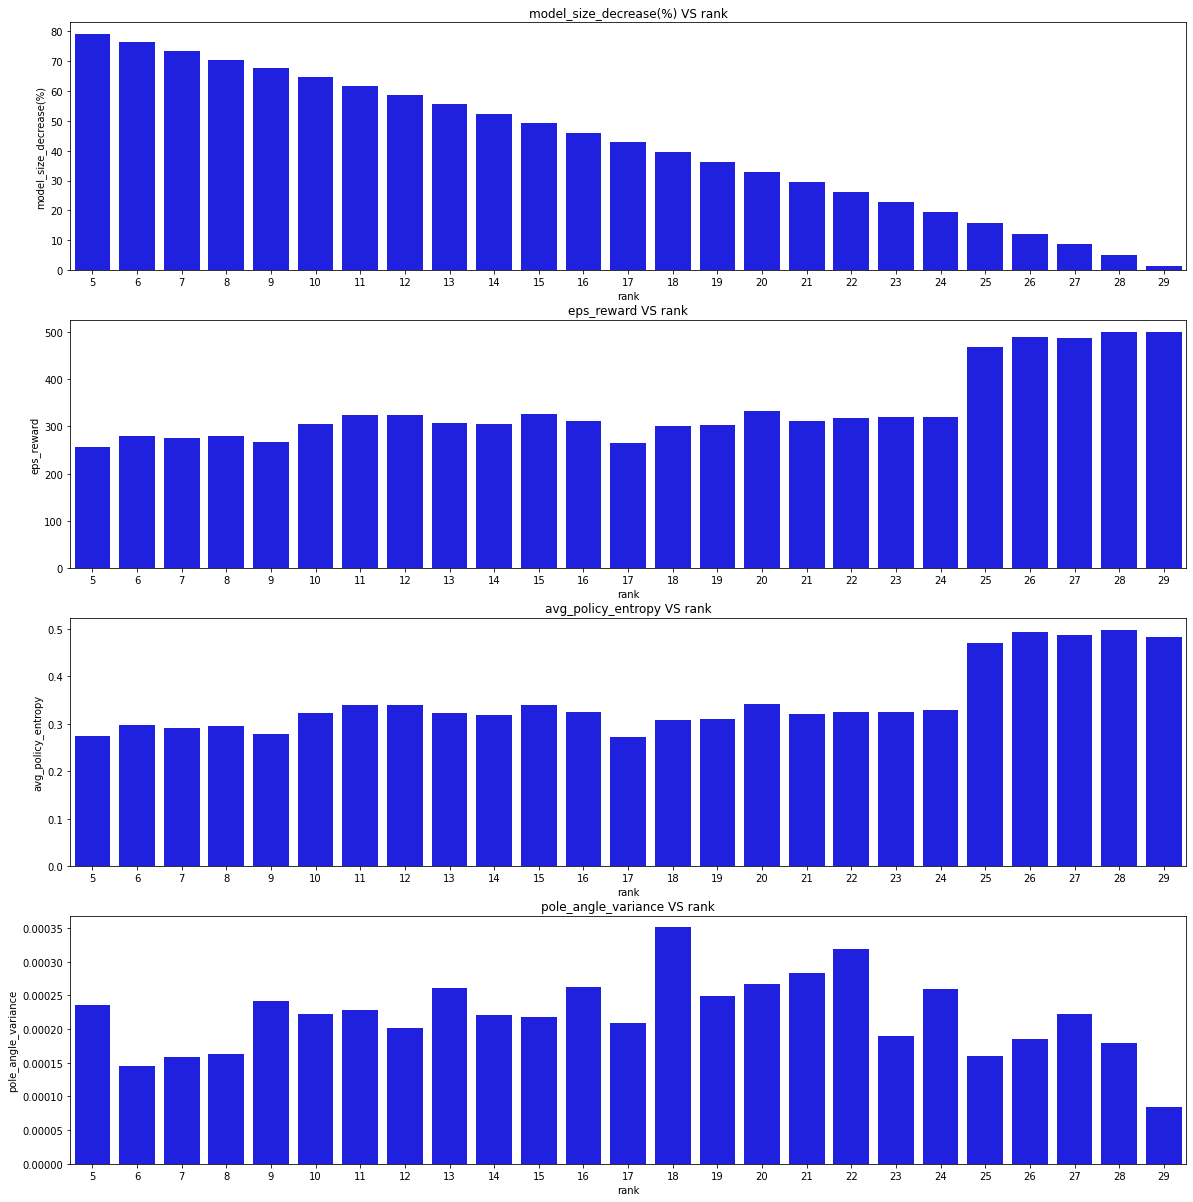

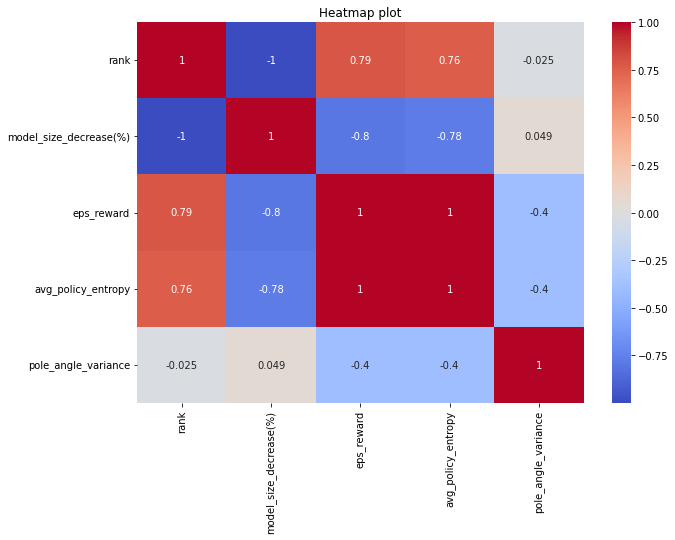

In [4]:
result = dict()
result["rank"] = []
result["model_size_decrease(%)"] = []
result["eps_reward"] = []
result["avg_policy_entropy"] = []
result["pole_angle_variance"] = []

for rank in tqdm(ranks):
    lra_dense_policy_agent, p = low_rank_approximate_policy(dense_policy_agent, rank)
    eps_reward, avg_policy_entropy, pole_angle_variance = run_evaluation(lra_dense_policy_agent, verbose=False)

    result["rank"].append(rank)
    result["model_size_decrease(%)"].append(p*100)
    result["eps_reward"].append(eps_reward)
    result["avg_policy_entropy"].append(avg_policy_entropy)
    result["pole_angle_variance"].append(pole_angle_variance)
    
result = pd.DataFrame(result)
plot_result_dataframe(result, x_axis="rank", plot_type="bar", with_heatmap=True)
result.to_csv(os.path.join(results_dir, "DQN_dense_policy_decomposition.csv"), index=False)

## Low Rank Approximation for Sparse Policy

#### **Evaluate Sparse Policy**

In [5]:
sparse_weights_filename = "CartPolev1_DQN_sparse_agent.pth.tar"
sparse_policy_agent = SparsePolicyNet(observation_space, action_space, hidden_size).to(os.getenv("DEVICE"))
sparse_policy_agent.load_state_dict(torch.load(os.path.join("params", sparse_weights_filename), map_location=os.getenv("DEVICE")))

result_df = run_evaluation(sparse_policy_agent, verbose=True)

Evaluation reward of policy: 500.0
Average policy entropy of policy: 0.6327478
Pole angle variance of policy: 5.93e-05 rads


#### **Evaluate Low Rank Approximated Sparse Policy**

  0%|          | 0/25 [00:00<?, ?it/s]

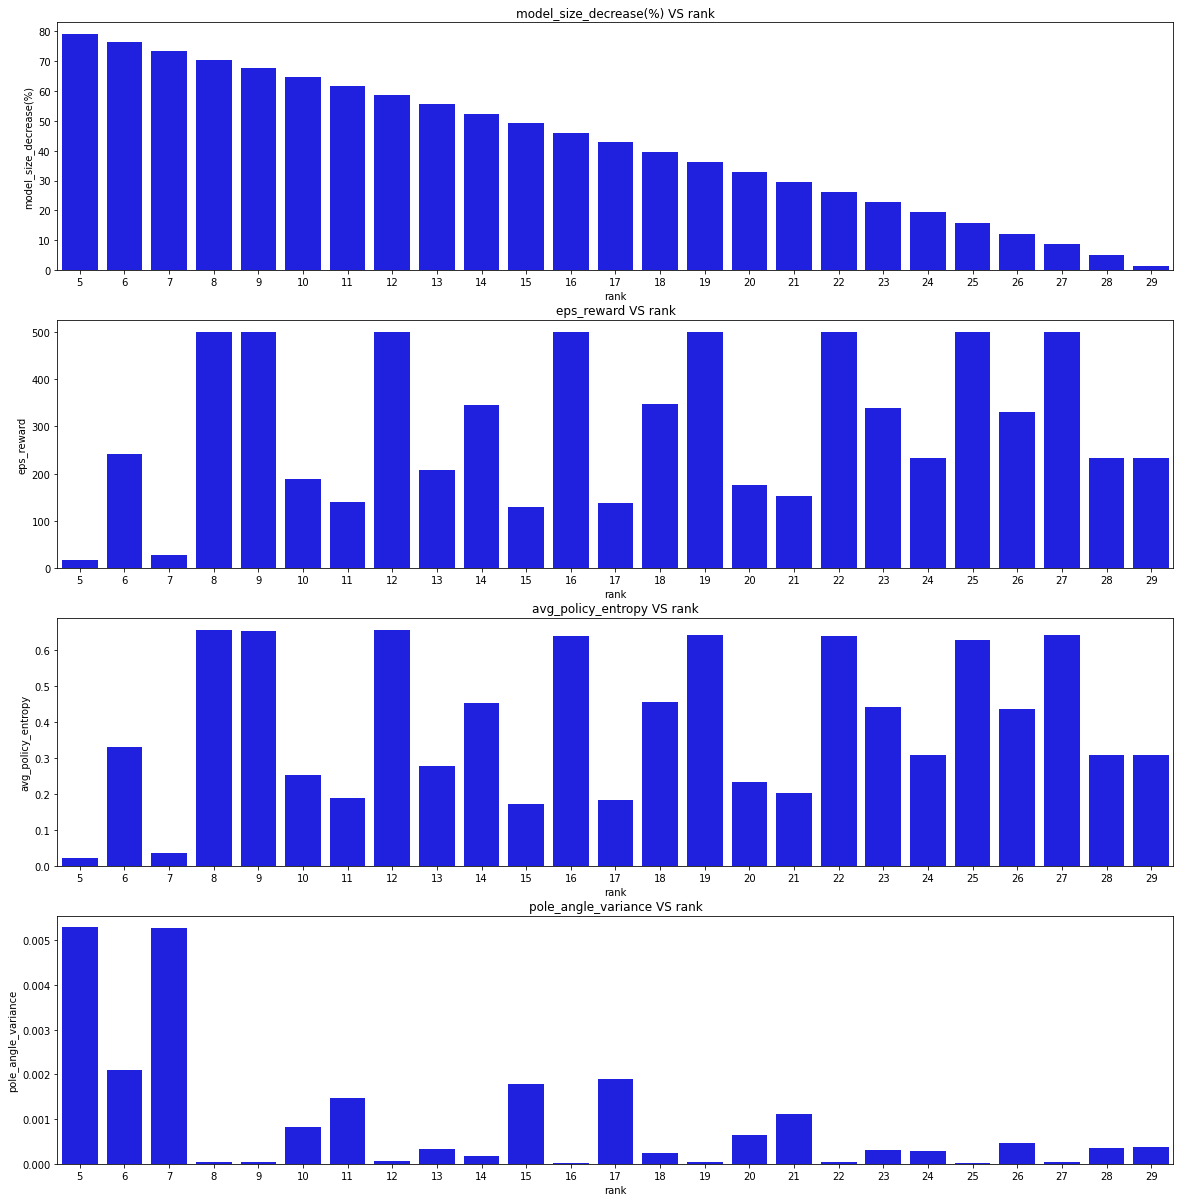

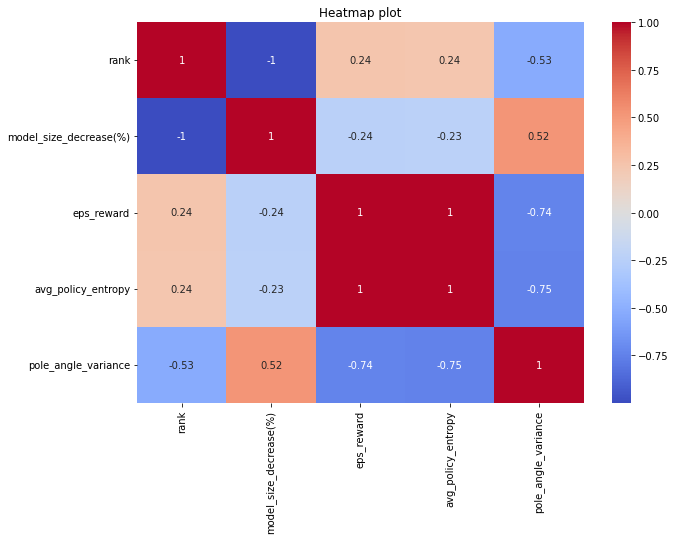

,rank,model_size_decrease(%),eps_reward,avg_policy_entropy,pole_angle_variance
0,5,78.880638,17.0,0.023059,0.005290
1,6,76.073175,242.0,0.329503,0.002097
2,7,73.229487,28.0,0.037100,0.005286
3,8,70.349574,500.0,0.655757,0.000047
4,9,67.433436,500.0,0.651558,0.000045
5,10,64.481072,188.0,0.251801,0.000822
6,11,61.492483,141.0,0.188605,0.001469
7,12,58.467669,500.0,0.654535,0.000051
8,13,55.406629,208.0,0.278207,0.000335
9,14,52.309364,345.0,0.451720,0.000167


In [6]:
result = dict()
result["rank"] = []
result["model_size_decrease(%)"] = []
result["eps_reward"] = []
result["avg_policy_entropy"] = []
result["pole_angle_variance"] = []

for rank in tqdm(ranks):
    lra_sparse_policy_agent, p = low_rank_approximate_policy(sparse_policy_agent, rank)
    eps_reward, avg_policy_entropy, pole_angle_variance = run_evaluation(lra_sparse_policy_agent, verbose=False)

    result["rank"].append(rank)
    result["model_size_decrease(%)"].append(p*100)
    result["eps_reward"].append(eps_reward)
    result["avg_policy_entropy"].append(avg_policy_entropy)
    result["pole_angle_variance"].append(pole_angle_variance)

result = pd.DataFrame(result)
plot_result_dataframe(result, x_axis="rank", plot_type="bar", with_heatmap=True)
result.to_csv(os.path.join(results_dir, "DQN_sparse_policy_decomposition.csv"), index=False)
result

In [7]:
del dense_policy_agent, sparse_policy_agent, lra_dense_policy_agent, lra_sparse_policy_agent, result
gc.collect()
torch.cuda.empty_cache()

# Low Rank Approximation of PPO Policies

#### **Evaluate Dense Policy**

In [4]:
dense_weights_filename = "CartPolev1_PPO_dense_policy_agent.pth.tar"
dense_policy_agent = PolicyNet(observation_space, action_space, hidden_size).to(os.getenv("DEVICE"))
dense_policy_agent.load_state_dict(torch.load(os.path.join("params", dense_weights_filename), map_location=os.getenv("DEVICE")))

run_evaluation(dense_policy_agent, verbose=True)

Evaluation reward of policy: 500.0
Average policy entropy of policy: 0.6115037
Pole angle variance of policy: 2.31e-05 rads


(500.0, 0.6115036581158638, 2.3060248372842353e-05)

#### **Evaluate Low Rank Approximated Dense Policy**

  0%|          | 0/25 [00:00<?, ?it/s]

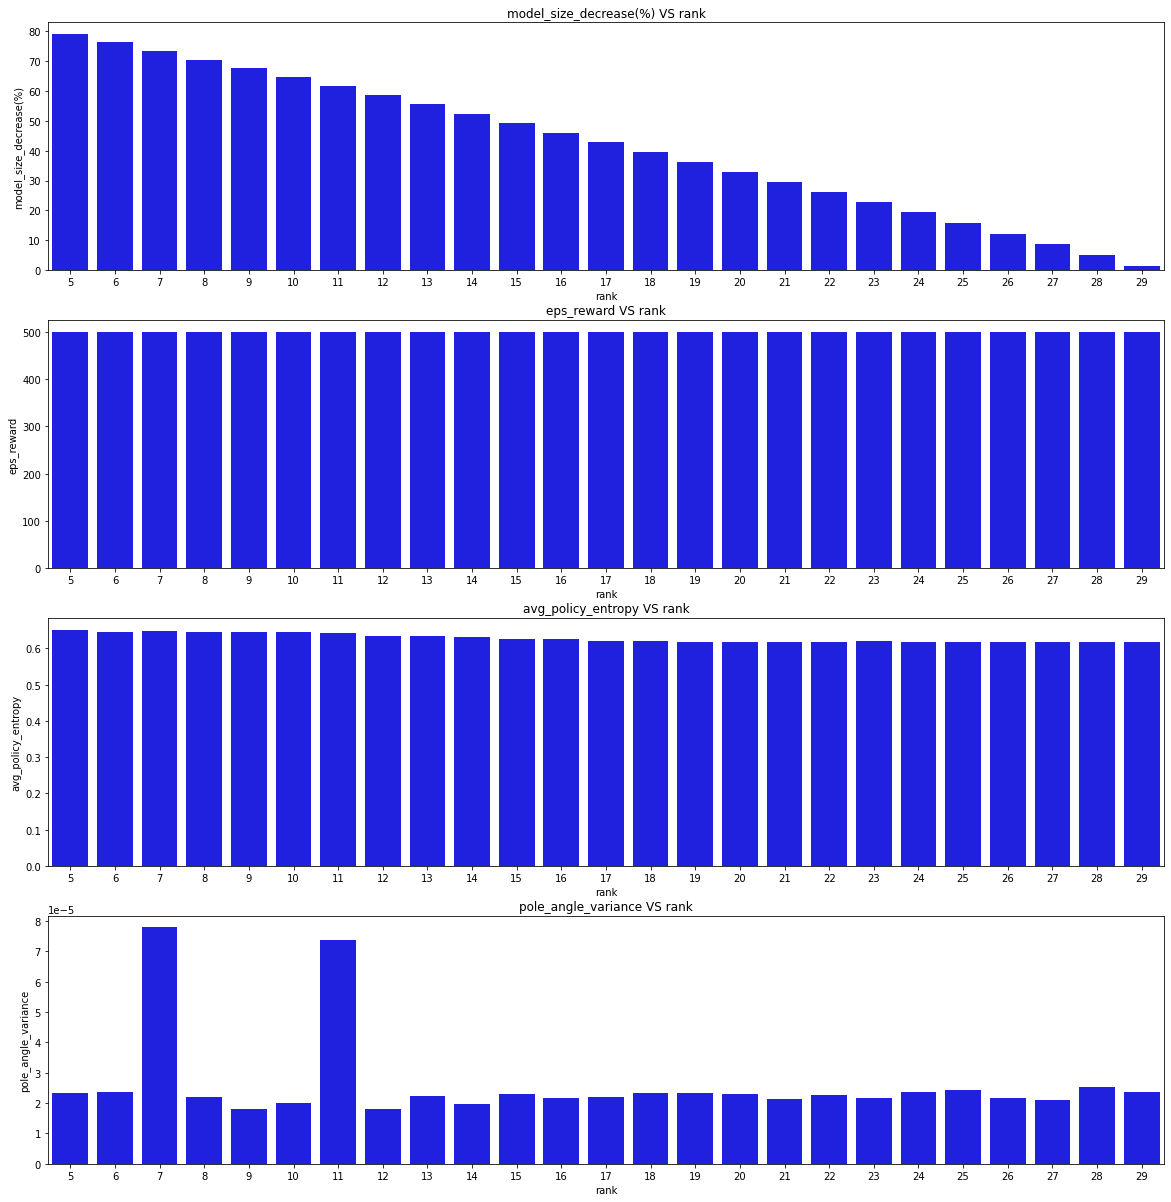

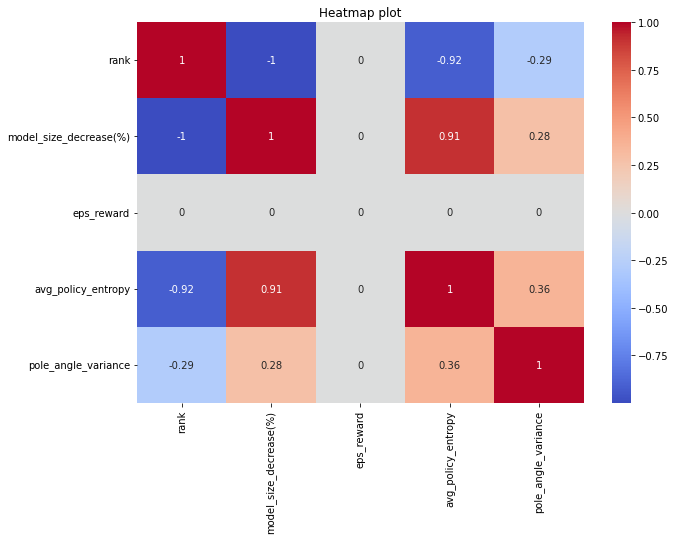

In [5]:
result = dict()
result["rank"] = []
result["model_size_decrease(%)"] = []
result["eps_reward"] = []
result["avg_policy_entropy"] = []
result["pole_angle_variance"] = []

for rank in tqdm(ranks):
    lra_dense_policy_agent, p = low_rank_approximate_policy(dense_policy_agent, rank)
    eps_reward, avg_policy_entropy, pole_angle_variance = run_evaluation(lra_dense_policy_agent, verbose=False)

    result["rank"].append(rank)
    result["model_size_decrease(%)"].append(p*100)
    result["eps_reward"].append(eps_reward)
    result["avg_policy_entropy"].append(avg_policy_entropy)
    result["pole_angle_variance"].append(pole_angle_variance)
    
result = pd.DataFrame(result)
plot_result_dataframe(result, x_axis="rank", plot_type="bar", with_heatmap=True)
result.to_csv(os.path.join(results_dir, "PPO_dense_policy_decomposition.csv"), index=False)

#### **Evaluate Sparse Policy**

In [6]:
sparse_weights_filename = "CartPolev1_PPO_sparse_policy_agent.pth.tar"
sparse_policy_agent = SparsePolicyNet(observation_space, action_space, hidden_size).to(os.getenv("DEVICE"))
sparse_policy_agent.load_state_dict(torch.load(os.path.join("params", sparse_weights_filename), map_location=os.getenv("DEVICE")))

result_df = run_evaluation(sparse_policy_agent, verbose=True)

Evaluation reward of policy: 500.0
Average policy entropy of policy: 0.6228877
Pole angle variance of policy: 2.95e-05 rads


#### **Evaluate Low Rank Approximated Sparse Policy**

  0%|          | 0/25 [00:00<?, ?it/s]

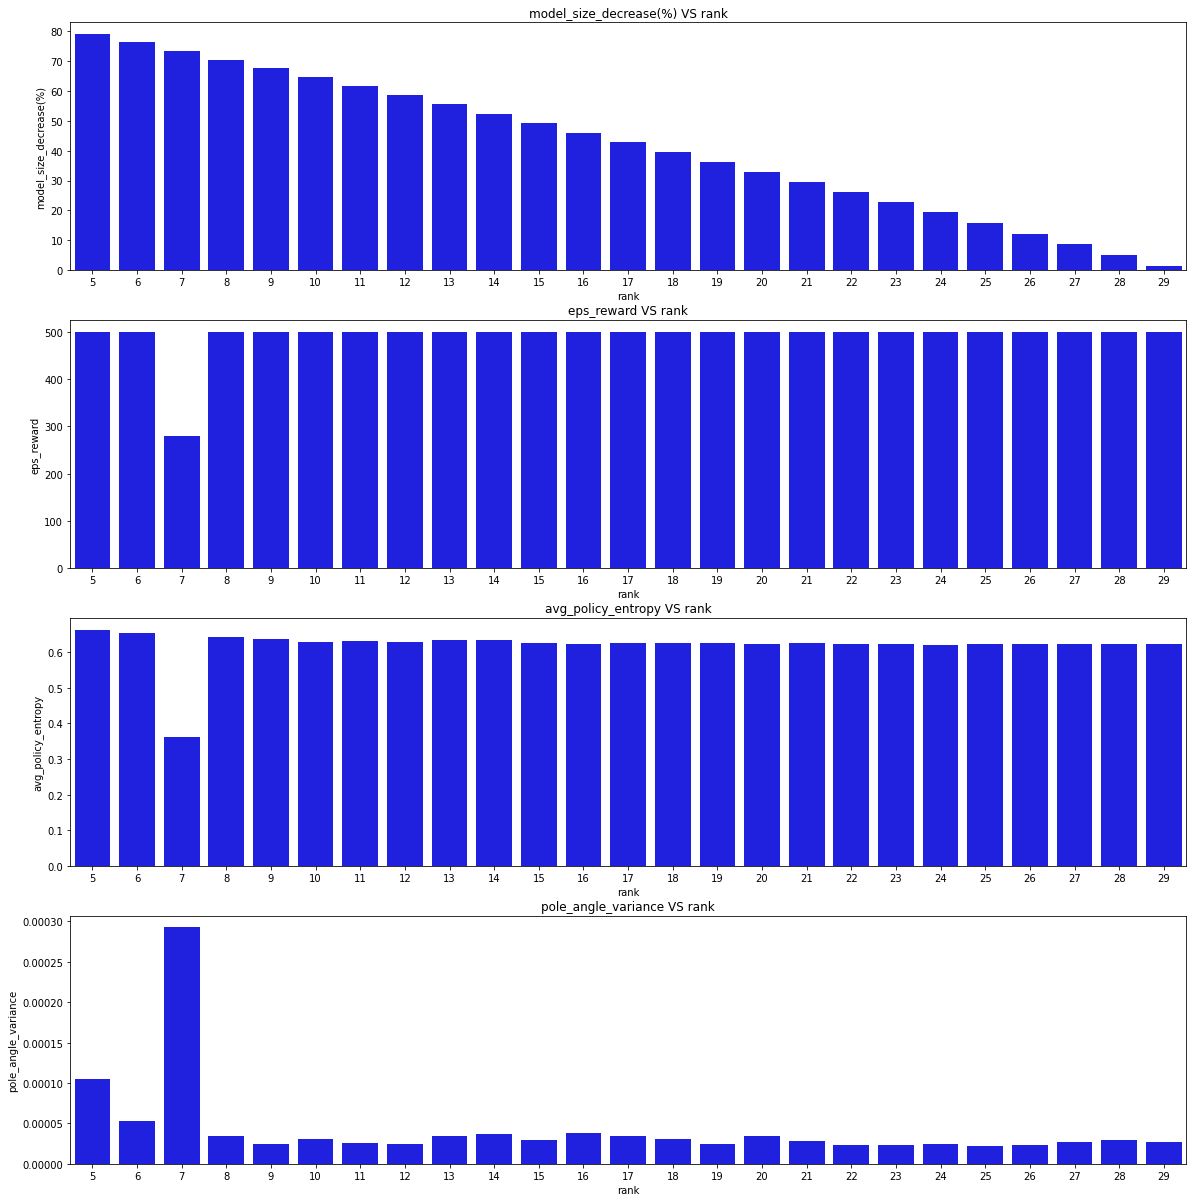

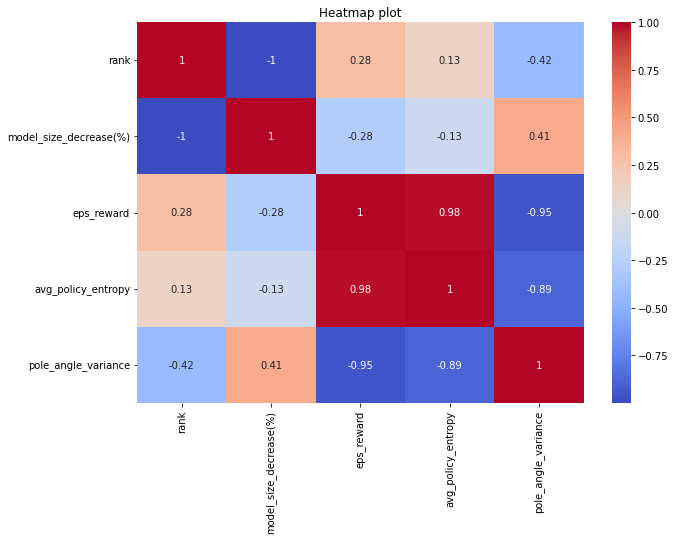

In [7]:
result = dict()
result["rank"] = []
result["model_size_decrease(%)"] = []
result["eps_reward"] = []
result["avg_policy_entropy"] = []
result["pole_angle_variance"] = []

for rank in tqdm(ranks):
    lra_sparse_policy_agent, p = low_rank_approximate_policy(sparse_policy_agent, rank)
    eps_reward, avg_policy_entropy, pole_angle_variance = run_evaluation(lra_sparse_policy_agent, verbose=False)

    result["rank"].append(rank)
    result["model_size_decrease(%)"].append(p*100)
    result["eps_reward"].append(eps_reward)
    result["avg_policy_entropy"].append(avg_policy_entropy)
    result["pole_angle_variance"].append(pole_angle_variance)

result = pd.DataFrame(result)
plot_result_dataframe(result, x_axis="rank", plot_type="bar", with_heatmap=True)
result.to_csv(os.path.join(results_dir, "PPO_sparse_policy_decomposition.csv"), index=False)

In [8]:
del dense_policy_agent, sparse_policy_agent, lra_dense_policy_agent, lra_sparse_policy_agent, result
gc.collect()
torch.cuda.empty_cache()